# 05 — Next-Token Prediction and the Language Modeling Objective

> **Goal:** Understand exactly what an autoregressive language model learns, how its predictions become probabilities, how cross-entropy measures prediction quality, and how perplexity summarizes that quality.

This notebook connects directly to Notebook 04. There, we converted text into token-ID sequences and created next-token input/target pairs. Here, we study the mathematical objective those pairs are used to train.

**Learning path:** intuition → probability → logits and softmax → negative log-likelihood → cross-entropy → padding masks → perplexity.

We will use **NumPy** to calculate everything transparently. We are not training a neural network yet; that comes later.


## 1. The central idea: predict the next token

A language model reads a sequence of tokens and predicts what token is likely to come next.

For example, suppose the input is:

`[The, cat, sat, on, the]`

The model might assign probabilities to possible next tokens:

| Candidate next token | Probability |
|---|---:|
| mat | 0.60 |
| floor | 0.20 |
| chair | 0.10 |
| roof | 0.05 |
| other tokens | 0.05 |

The model's job is not to retrieve a memorized sentence. It learns statistical patterns that help it estimate a distribution over the next token.

This is called **autoregressive** prediction: each next-token prediction is conditioned on the tokens that came before it.


## 2. Autoregressive probability: the chain rule

Let a token sequence be:

\[
x_1, x_2, \ldots, x_T
\]

The probability of the complete sequence can be factorized using the probability chain rule:

\[
P(x_1,\ldots,x_T)
=
P(x_1)P(x_2\mid x_1)\cdots
P(x_T\mid x_1,\ldots,x_{T-1})
\]

More compactly:

\[
\boxed{P(x_{1:T})=\prod_{t=1}^{T}P(x_t\mid x_{<t})}
\]

Here, \(x_{<t}\) means every token before position \(t\).

A model therefore learns to estimate:

\[
P(x_t\mid x_1,\ldots,x_{t-1})
\]

At each position, it predicts the actual next token using the preceding context.

**Important:** the factorization is a mathematical identity from the chain rule. The neural network is the mechanism we later use to estimate each conditional probability.


### A tiny sequence example

Consider the token sequence:

`[I, like, small, models]`

The training examples are:

| Context (input) | Correct next token (target) |
|---|---|
| I | like |
| I like | small |
| I like small | models |

A causal language model can produce a prediction at every position. The target is the token one position to the right.


In [1]:
tokens = ["I", "like", "small", "models"]

for position in range(1, len(tokens)):
    context = tokens[:position]
    target = tokens[position]
    print(f"Context: {context!s:25} -> target: {target}")

Context: ['I']                     -> target: like
Context: ['I', 'like']             -> target: small
Context: ['I', 'like', 'small']    -> target: models


## 3. From Notebook 04: input and target shifting

In Notebook 04, a sequence such as:

`[BOS, I, like, small, EOS]`

was shifted into:

- **Input:** `[BOS, I, like, small]`
- **Target:** `[I, like, small, EOS]`

The model receives the input and is trained to predict the target at each corresponding position.

Notice that input and target have the same length. The target is simply shifted one token to the left relative to the input.



In [2]:
sequence = ["<bos>", "I", "like", "small", "<eos>"]

input_tokens = sequence[:-1]
target_tokens = sequence[1:]

print("Input: ", input_tokens)
print("Target:", target_tokens)

for x, y in zip(input_tokens, target_tokens):
    print(f"When the model sees {x!r:8}, it should predict {y!r}")

Input:  ['<bos>', 'I', 'like', 'small']
Target: ['I', 'like', 'small', '<eos>']
When the model sees '<bos>' , it should predict 'I'
When the model sees 'I'     , it should predict 'like'
When the model sees 'like'  , it should predict 'small'
When the model sees 'small' , it should predict '<eos>'


## 4. Logits: the model's raw scores

A neural language model does not usually output probabilities directly. Its final layer produces one raw score for every token in the vocabulary. These scores are called **logits**.

Suppose our vocabulary has five tokens:

`["cat", "dog", "mat", "runs", "the"]`

The model might output:



In [3]:
import numpy as np

vocabulary = ["cat", "dog", "mat", "runs", "the"]
logits = np.array([1.2, 0.3, 2.4, -0.5, 0.8])

for token, score in zip(vocabulary, logits):
    print(f"{token:>5}: {score:>6.2f}")

  cat:   1.20
  dog:   0.30
  mat:   2.40
 runs:  -0.50
  the:   0.80


A logit is **not** a probability:

- It can be negative.
- It can be greater than 1.
- The logits do not have to add up to 1.
- A larger logit means the model currently scores that token more highly than tokens with smaller logits.

We need to convert logits into a valid probability distribution. That is the job of softmax.


## 5. Softmax: converting logits into probabilities

For logits \(z_1,\ldots,z_V\), softmax produces:

\[
\boxed{p_i=\frac{e^{z_i}}{\sum_{j=1}^{V}e^{z_j}}}
\]

where \(V\) is the vocabulary size.

The resulting values have two important properties:

1. Every probability is between 0 and 1.
2. All probabilities sum to 1.

### Why exponentials?

Exponentiation makes every score positive and gives higher scores more weight. Dividing by the sum normalizes the values into a probability distribution.

### Numerical stability

For large logits, \(e^{z_i}\) can overflow. Softmax is unchanged if we subtract the same constant from every logit. We therefore subtract the maximum logit:

\[
p_i=
\frac{e^{z_i-\max(z)}}{\sum_j e^{z_j-\max(z)}}
\]

This is the stable form used in our implementation.


In [4]:
def softmax(logits):
    # Convert to float for reliable numerical operations.
    logits = np.asarray(logits, dtype=np.float64)
    shifted = logits - np.max(logits)
    exponentials = np.exp(shifted)
    return exponentials / np.sum(exponentials)

probabilities = softmax(logits)

for token, probability in zip(vocabulary, probabilities):
    print(f"{token:>5}: {probability:.4f}")

print("\nProbability sum:", probabilities.sum())

  cat: 0.1792
  dog: 0.0729
  mat: 0.5950
 runs: 0.0327
  the: 0.1201

Probability sum: 1.0


### Experiment: what happens when one logit increases?

Try changing the score for `mat`. A higher score should generally increase its probability, while the other probabilities shrink because the total must remain 1.


In [5]:
def show_distribution(scores, words):
    probs = softmax(scores)
    for word, prob in zip(words, probs):
        print(f"{word:>5}: {prob:.4f}")
    print("sum:", probs.sum())

print("Original:")
show_distribution([1.2, 0.3, 2.4, -0.5, 0.8], vocabulary)

print("\nWith a much higher score for 'mat':")
show_distribution([1.2, 0.3, 5.0, -0.5, 0.8], vocabulary)

Original:
  cat: 0.1792
  dog: 0.0729
  mat: 0.5950
 runs: 0.0327
  the: 0.1201
sum: 1.0

With a much higher score for 'mat':
  cat: 0.0213
  dog: 0.0087
  mat: 0.9519
 runs: 0.0039
  the: 0.0143
sum: 1.0


## 6. The correct token and its probability

During training, we know the correct next token because it comes from the training text.

Suppose the correct next token is `mat`. The model's probability for `mat` is the probability assigned to the target token.

If the model assigns:
- 0.90 to `mat`, that is a confident and correct prediction.
- 0.20 to `mat`, the model is less certain.
- 0.001 to `mat`, the model has assigned very little probability to the correct answer.

We need a numerical way to penalize low probability assigned to the correct token. This leads to negative log-likelihood.


## 7. Negative log-likelihood (NLL)

For one prediction, let \(p_{\text{correct}}\) be the probability assigned to the actual next token.

The negative log-likelihood loss is:

\[
\boxed{L=-\log(p_{\text{correct}})}
\]

Why the negative logarithm?

- If the correct token gets probability close to 1, loss is close to 0.
- If the correct token gets a small probability, loss becomes large.
- Assigning probability 0 would produce infinite loss, so implementations use numerically safe log-softmax calculations.

Some examples:

\[
-\log(1.0)=0
\]

\[
-\log(0.5)\approx 0.693
\]

\[
-\log(0.1)\approx 2.303
\]

The logarithm is the natural logarithm here (base \(e\)).


In [6]:
target_probabilities = np.array([1.0, 0.5, 0.1, 0.01, 0.001])
nll_values = -np.log(target_probabilities)

for p, loss in zip(target_probabilities, nll_values):
    print(f"Correct-token probability = {p:>7.3f} | NLL = {loss:.4f}")

Correct-token probability =   1.000 | NLL = -0.0000
Correct-token probability =   0.500 | NLL = 0.6931
Correct-token probability =   0.100 | NLL = 2.3026
Correct-token probability =   0.010 | NLL = 4.6052
Correct-token probability =   0.001 | NLL = 6.9078


### A quick visual intuition

As the probability assigned to the correct token increases, the loss falls. A model is rewarded for assigning high probability to the actual next token.


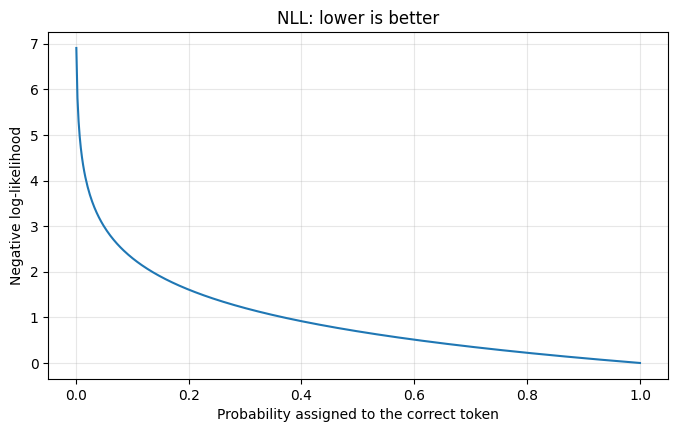

In [7]:
import matplotlib.pyplot as plt

p_values = np.linspace(0.001, 1.0, 500)
loss_values = -np.log(p_values)

plt.figure(figsize=(8, 4.5))
plt.plot(p_values, loss_values)
plt.xlabel("Probability assigned to the correct token")
plt.ylabel("Negative log-likelihood")
plt.title("NLL: lower is better")
plt.grid(True, alpha=0.3)
plt.show()

## 8. Calculate one prediction's loss by hand

Suppose the model predicts the following distribution:

| Token | Probability |
|---|---:|
| cat | 0.10 |
| dog | 0.15 |
| mat | 0.60 |
| runs | 0.05 |
| the | 0.10 |

The actual next token is `mat`. Therefore:

\[
L=-\ln(0.60)\approx 0.5108
\]

Let's verify this with Python.

In [8]:
toy_probs = np.array([0.10, 0.15, 0.60, 0.05, 0.10])
toy_tokens = ["cat", "dog", "mat", "runs", "the"]
actual_token = "mat"

target_index = toy_tokens.index(actual_token)
correct_probability = toy_probs[target_index]
loss = -np.log(correct_probability)

print("Actual token:", actual_token)
print("Probability assigned to it:", correct_probability)
print("NLL:", loss)

Actual token: mat
Probability assigned to it: 0.6
NLL: 0.5108256237659907


## 9. Cross-entropy: loss over many predictions

A language model predicts many next tokens in a sequence, and it does this for many sequences in a batch.

For \(N\) valid prediction positions, the average cross-entropy loss is:

\[
\boxed{
\mathcal{L}
=
-\frac{1}{N}\sum_{n=1}^{N}\log p_\theta(y_n\mid c_n)
}
\]

where:
- \(y_n\) is the correct next token,
- \(c_n\) is its preceding context,
- \(p_\theta\) is the model's predicted probability distribution,
- \(N\) is the number of included prediction positions.

For a one-hot target (exactly one correct token), cross-entropy is the same as the negative log probability of the correct token.

**Training objective:** adjust the model's parameters so that the average cross-entropy on training examples decreases.

### Cross-entropy from a matrix of logits

Imagine a sequence with three prediction positions and a vocabulary of four tokens. Each row contains logits for one position. The target array tells us the correct token index at each position.


In [9]:
# Shape: (number of positions, vocabulary size)
batch_logits = np.array([
    [2.0, 0.5, 0.1, -0.2],
    [0.2, 1.8, 0.4,  0.0],
    [0.1, 0.3, 2.2,  0.5],
])

# Correct token index at each position
targets = np.array([0, 1, 2])

def cross_entropy_from_logits(logits_2d, target_ids):
    logits_2d = np.asarray(logits_2d, dtype=np.float64)
    target_ids = np.asarray(target_ids, dtype=np.int64)

    shifted = logits_2d - np.max(logits_2d, axis=1, keepdims=True)
    log_sum_exp = np.log(np.sum(np.exp(shifted), axis=1, keepdims=True))
    log_probabilities = shifted - log_sum_exp

    row_indices = np.arange(len(target_ids))
    per_position_losses = -log_probabilities[row_indices, target_ids]
    return per_position_losses.mean(), per_position_losses

mean_loss, position_losses = cross_entropy_from_logits(batch_logits, targets)

print("Per-position losses:", np.round(position_losses, 4))
print("Mean cross-entropy:", round(mean_loss, 4))

Per-position losses: [0.3944 0.4786 0.3748]
Mean cross-entropy: 0.4159


The implementation uses the stable **log-softmax** identity:

\[
\log \operatorname{softmax}(z_i)
=
(z_i-m)-\log\left(\sum_j e^{z_j-m}\right)
\]

where \(m=\max_j z_j\).

It does not need to create a separate probability matrix first. This is more numerically stable than taking the logarithm of tiny softmax probabilities.

## 10. Why average the losses?

Each token prediction has its own loss. Averaging gives one scalar objective for the batch.

Let's compare two toy models on the same targets:
- Model A gives the correct token a high probability most of the time.
- Model B gives the correct token a lower probability.

The model with lower mean NLL is better on these examples.


In [10]:
model_a_correct_probs = np.array([0.80, 0.70, 0.90, 0.60])
model_b_correct_probs = np.array([0.30, 0.40, 0.20, 0.50])

model_a_loss = -np.log(model_a_correct_probs).mean()
model_b_loss = -np.log(model_b_correct_probs).mean()

print(f"Model A mean NLL: {model_a_loss:.4f}")
print(f"Model B mean NLL: {model_b_loss:.4f}")

Model A mean NLL: 0.2990
Model B mean NLL: 1.1057


## 11. Padding tokens and masked loss

Batches often contain sequences of different lengths. To make them the same length, shorter sequences are padded with `<pad>` tokens.

But padding is not real text. We generally do **not** want the model to be penalized for failing to predict padding positions.

A mask identifies which target positions should contribute to the loss:

- `1` (or `True`): include this position.
- `0` (or `False`): ignore this position.

The masked mean loss is:

\[
\boxed{
\mathcal{L}_{masked}
=
\frac{\sum_i m_i L_i}{\sum_i m_i}
}
\]

where \(m_i\) is the mask and \(L_i\) is the loss at position \(i\).

In [11]:
per_position_losses = np.array([0.20, 0.70, 1.10, 8.00, 8.00])
# The final two target positions are padding.
loss_mask = np.array([1, 1, 1, 0, 0], dtype=bool)

unmasked_mean = per_position_losses.mean()
masked_mean = per_position_losses[loss_mask].mean()

print("All-position mean (incorrect if last two are padding):", unmasked_mean)
print("Masked mean (ignores padding):", masked_mean)

All-position mean (incorrect if last two are padding): 3.6
Masked mean (ignores padding): 0.6666666666666666


**Important distinction:** a loss mask controls which target positions contribute to the loss. A causal attention mask controls which positions can attend to which other positions. They solve different problems.

Also, masking padded target positions does not automatically prevent attention to padding tokens. The model's attention implementation must handle padding appropriately too.


## 12. Perplexity: a more interpretable view of loss

Perplexity is a transformation of average negative log-likelihood:

\[
\boxed{\operatorname{PPL}=\exp(\mathcal{L})}
\]

If the average NLL is measured using natural logarithms, exponentiating it gives perplexity.

Examples:
- NLL = 0 → perplexity = 1
- NLL ≈ 0.693 → perplexity ≈ 2
- NLL ≈ 2.303 → perplexity ≈ 10

A lower perplexity means the model assigned higher probability to the observed tokens on average.

In [12]:
example_nll = np.array([0.2, 0.7, 1.1, 0.5])
mean_nll = example_nll.mean()
perplexity = np.exp(mean_nll)

print("Mean NLL:", round(mean_nll, 4))
print("Perplexity:", round(perplexity, 4))

Mean NLL: 0.625
Perplexity: 1.8682


### Perplexity intuition

A rough intuition is that perplexity behaves like the model's effective number of plausible choices at each position.

- Perplexity near 1: the model is very confident about the observed tokens.
- Higher perplexity: the model spreads probability more broadly or assigns less probability to the observed tokens.

This is an intuition, not a literal count of choices in every context.


## 13. A complete miniature loss calculation

Let's put the pieces together:

1. Start with logits at each prediction position.
2. Convert logits to log-probabilities using stable log-softmax.
3. Select the log-probability of the correct target token.
4. Negate it to get NLL at each position.
5. Apply a mask if some positions should be ignored.
6. Average the included losses.
7. Exponentiate the mean loss to get perplexity.


In [13]:
def language_model_metrics(logits_2d, target_ids, mask=None):
    logits_2d = np.asarray(logits_2d, dtype=np.float64)
    target_ids = np.asarray(target_ids, dtype=np.int64)

    if logits_2d.ndim != 2:
        raise ValueError("logits_2d must have shape (positions, vocabulary_size)")
    if len(target_ids) != logits_2d.shape[0]:
        raise ValueError("There must be one target ID per logits row.")
    if np.any(target_ids < 0) or np.any(target_ids >= logits_2d.shape[1]):
        raise ValueError("A target ID is outside the vocabulary.")

    shifted = logits_2d - logits_2d.max(axis=1, keepdims=True)
    log_probs = shifted - np.log(np.exp(shifted).sum(axis=1, keepdims=True))
    losses = -log_probs[np.arange(len(target_ids)), target_ids]

    if mask is None:
        mask = np.ones(len(target_ids), dtype=bool)
    else:
        mask = np.asarray(mask, dtype=bool)

    if len(mask) != len(target_ids):
        raise ValueError("Mask length must match the number of positions.")
    if not mask.any():
        raise ValueError("At least one position must be included in the loss.")

    mean_nll = losses[mask].mean()
    return {
        "per_position_nll": losses,
        "mean_nll": mean_nll,
        "perplexity": np.exp(mean_nll),
        "included_positions": int(mask.sum()),
    }

demo_logits = np.array([
    [2.0, 0.5, 0.1, -0.2],
    [0.2, 1.8, 0.4,  0.0],
    [0.1, 0.3, 2.2,  0.5],
    [0.0, 0.1, 0.2,  2.0],
])
demo_targets = np.array([0, 1, 2, 3])
demo_mask = np.array([1, 1, 1, 0], dtype=bool)

metrics = language_model_metrics(demo_logits, demo_targets, demo_mask)

print("Per-position NLL:", np.round(metrics["per_position_nll"], 4))
print("Included positions:", metrics["included_positions"])
print("Mean NLL:", round(metrics["mean_nll"], 4))
print("Perplexity:", round(metrics["perplexity"], 4))

Per-position NLL: [0.3944 0.4786 0.3748 0.3717]
Included positions: 3
Mean NLL: 0.4159
Perplexity: 1.5158


## 14. What does the training loop eventually do?

We are not implementing the neural network in this notebook, but it helps to understand where the objective fits.

A future training step will roughly look like this:

1. Take a batch of token-ID inputs and shifted targets.
2. Run the input tokens through the model.
3. Get logits for every position and vocabulary token.
4. Calculate cross-entropy between logits and targets.
5. Ignore padded target positions using the loss mask.
6. Backpropagate the loss to calculate gradients.
7. Use an optimizer to update model parameters.
8. Repeat for many batches.

The model learns because gradient-based optimization changes its parameters to reduce the probability penalty on the correct next tokens.

We will implement the neural network and training loop in later notebooks.


## 15. Common misunderstandings

| Misunderstanding | Correct interpretation |
|---|---|
| Logits are probabilities | Logits are raw scores; softmax converts them into probabilities. |
| The model predicts a whole sentence in one step | Autoregressive generation predicts one next token at a time. |
| Cross-entropy compares two ordinary sentences | In language-model training, it measures the probability assigned to the correct target token at each position. |
| Lower loss is always better in every situation | Lower evaluation loss is useful, but data quality, distribution, leakage and task performance matter too. |
| Perplexity is accuracy | Perplexity measures average predictive uncertainty, not the fraction of exact matches. |
| Padding should be learned like normal text | Padded target positions are usually excluded from the loss. |
| Loss mask and causal mask are identical | One masks loss positions; the other restricts attention. |


## 16. Exercises

Try these before looking at the answers.

1. If the model assigns probability `0.25` to the correct token, calculate its NLL.
2. If the mean NLL is `1.0`, calculate perplexity.
3. Why do we subtract the maximum logit before exponentiating in softmax?
4. A batch has 12 target positions, of which 3 are padding. How many positions should contribute to the masked mean loss?
5. If two models are evaluated on the same tokenized test set and Model A has lower cross-entropy, what does that tell you?
6. Why is perplexity not the same as next-token accuracy?

Use the cell below to calculate the first two answers.


In [14]:
print("NLL when p(correct) = 0.25:", -np.log(0.25))
print("Perplexity when mean NLL = 1.0:", np.exp(1.0))

NLL when p(correct) = 0.25: 1.3862943611198906
Perplexity when mean NLL = 1.0: 2.718281828459045


<details>
<summary><strong>Exercise answers</strong></summary>

1. \(-\ln(0.25)\approx 1.3863\).
2. \(\exp(1)\approx 2.7183\).
3. It improves numerical stability by preventing unnecessarily large exponentials; softmax is unchanged by subtracting the same constant from every logit.
4. \(12-3=9\) positions.
5. On that test set, Model A assigned higher probability to the observed next tokens on average.
6. Accuracy checks whether the top-ranked token is exactly correct. Perplexity uses the probability assigned to the correct token, so it also reflects confidence.

</details>

## 17. Notebook summary

You should now be comfortable with the core language-modeling objective:

- An autoregressive model estimates \(P(x_t\mid x_{<t})\).
- It produces logits over the vocabulary.
- Softmax converts logits into a probability distribution.
- Negative log-likelihood penalizes low probability assigned to the correct token.
- Cross-entropy averages that penalty across prediction positions.
- Padding masks exclude artificial padded targets from the loss.
- Perplexity is \(\exp(\text{mean NLL})\).

**The key idea:** pretraining a causal language model means learning model parameters that make the real next tokens in the training data receive high probability.

### Next notebook

**Notebook 06 — Building a Tiny Language Model with PyTorch**

We will move from NumPy calculations to a small trainable neural language model: embeddings, a simple architecture, logits, cross-entropy, a training loop, and generation. This is where PyTorch becomes useful.